# NASA Turbofan Engine Remaining Useful Life (RUL) Prediction

## Project overview
This notebook develops regression models to estimate the **Remaining Useful Life (RUL)** of turbofan engines using sensor measurements and operating settings from the NASA C-MAPSS dataset.

The experiments use the **FD001** subset. The training data contains run-to-failure histories; the official test data contains the final observed row for each test engine, with corresponding true RUL values supplied separately.

## Objectives
- Inspect engine operating settings and sensor measurements.
- Construct an RUL target from each training engine's final observed cycle.
- Compare baseline and regression models.
- Evaluate predictions using MAE, RMSE and R².
- Examine feature importance, residuals, learning behaviour and feature selection.
- Evaluate the selected model on the official FD001 test set.

## Notebook workflow
1. Dataset upload and extraction
2. Data loading and exploratory analysis
3. RUL target construction and feature preparation
4. Engine-wise training/validation split
5. Model training and comparison
6. Error analysis and feature experiments
7. Official test evaluation and ensemble comparison

> **Reproducibility note:** The first cell asks you to upload `CMAPSSData.zip` in Google Colab. The archive should contain the C-MAPSS text files. The notebook uses the FD001 files for the experiments below.


## 1. Dataset setup
Upload the C-MAPSS archive from your computer into the Colab runtime.

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving CMAPSSData.zip to CMAPSSData.zip


In [ ]:
import zipfile
import os

zip_path = "/content/CMAPSSData.zip"
extract_path = "/content/CMAPSSData"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("\nAvailable files:")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        print(file)

Dataset extracted successfully!

Available files:
test_FD002.txt
train_FD004.txt
test_FD004.txt
RUL_FD004.txt
Damage Propagation Modeling.pdf
train_FD003.txt
test_FD001.txt
RUL_FD003.txt
test_FD003.txt
RUL_FD001.txt
RUL_FD002.txt
readme.txt
train_FD001.txt
train_FD002.txt


## 2. Import libraries
Import the Python packages used for data handling, visualization, model training and evaluation.

In [ ]:
# 1. Data handling
import os
import numpy as np
import pandas as pd

# 2. Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Data preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectFromModel

# 4. Train-validation splitting
from sklearn.model_selection import train_test_split, learning_curve

# 5. Regression models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)

# 6. Model evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 7. Dimensionality reduction
from sklearn.decomposition import PCA

# 8. Display settings
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## 3. Load the FD001 training data
Read `train_FD001.txt` and assign column names to the engine identifier, operating cycle, three settings and 21 sensor measurements.

In [ ]:
import pandas as pd

data_dir = "/content/CMAPSSData"

columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train_df = pd.read_csv(
    f"{data_dir}/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset shape:", train_df.shape)
display(train_df.head())

Dataset shape: (20631, 26)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 4. Exploratory data analysis
### 4.1 Sensor summary statistics
Review the distribution and scale of the sensor measurements.

In [ ]:
# Summary statistics for the sensor measurements
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

display(train_df[sensor_columns].describe().round(2))

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.0,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.00,20631.0,20631.0,20631.00,20631.00
mean,518.67,642.68,1590.52,1408.93,14.62,21.61,553.37,2388.10,9065.24,1.3,47.54,521.41,2388.10,8143.75,8.44,0.03,393.21,2388.0,100.0,38.82,23.29
std,0.00,0.50,6.13,9.00,0.00,0.00,0.89,0.07,22.08,0.0,0.27,0.74,0.07,19.08,0.04,0.00,1.55,0.0,0.0,0.18,0.11
min,518.67,641.21,1571.04,1382.25,14.62,21.60,549.85,2387.90,9021.73,1.3,46.85,518.69,2387.88,8099.94,8.32,0.03,388.00,2388.0,100.0,38.14,22.89
25%,518.67,642.33,1586.26,1402.36,14.62,21.61,552.81,2388.05,9053.10,1.3,47.35,520.96,2388.04,8133.24,8.41,0.03,392.00,2388.0,100.0,38.70,23.22
50%,518.67,642.64,1590.10,1408.04,14.62,21.61,553.44,2388.09,9060.66,1.3,47.51,521.48,2388.09,8140.54,8.44,0.03,393.00,2388.0,100.0,38.83,23.30
75%,518.67,643.00,1594.38,1414.55,14.62,21.61,554.01,2388.14,9069.42,1.3,47.70,521.95,2388.14,8148.31,8.47,0.03,394.00,2388.0,100.0,38.95,23.37
max,518.67,644.53,1616.91,1441.49,14.62,21.61,556.06,2388.56,9244.59,1.3,48.53,523.38,2388.56,8293.72,8.58,0.03,400.00,2388.0,100.0,39.43,23.62


### 4.2 Identify constant sensors
Check which sensor columns have no variation in the training data.

In [ ]:
# Calculate standard deviation for each sensor
sensor_std = train_df[sensor_columns].std()

# Identify sensors with zero variation
constant_sensors = sensor_std[sensor_std == 0].index.tolist()

print("Constant sensors:", constant_sensors)
print("Number of constant sensors:", len(constant_sensors))

print("\nSensor standard deviations:")
display(sensor_std.sort_values().to_frame("Standard Deviation"))

Constant sensors: ['sensor_18', 'sensor_19']
Number of constant sensors: 2

Sensor standard deviations:


,Standard Deviation
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,1.556432e-14
sensor_10,4.660829e-13
sensor_5,3.394700e-12
sensor_1,6.537152e-11
sensor_6,1.388985e-03
sensor_15,3.750504e-02
sensor_8,7.098548e-02
sensor_13,7.191892e-02


### 4.3 Sensor behaviour over operating cycles
Visualize selected sensor measurements for one engine across its observed cycles.

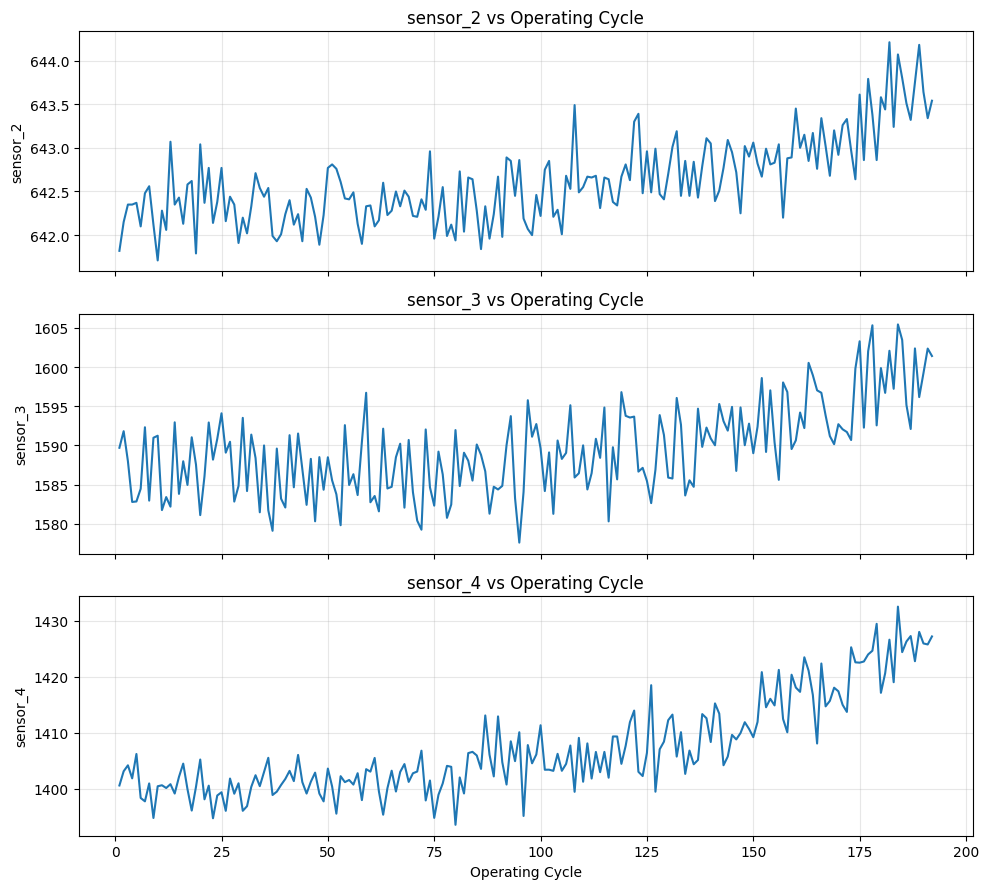

In [ ]:
# Select one engine for an initial visualization
engine_id = 1
engine_data = train_df[train_df["engine_id"] == engine_id]

selected_sensors = ["sensor_2", "sensor_3", "sensor_4"]

fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)

for ax, sensor in zip(axes, selected_sensors):
    ax.plot(engine_data["cycle"], engine_data[sensor])
    ax.set_ylabel(sensor)
    ax.set_title(f"{sensor} vs Operating Cycle")
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Operating Cycle")
plt.tight_layout()
plt.show()

### 4.4 Sensor correlation
Inspect pairwise correlations between sensor measurements.

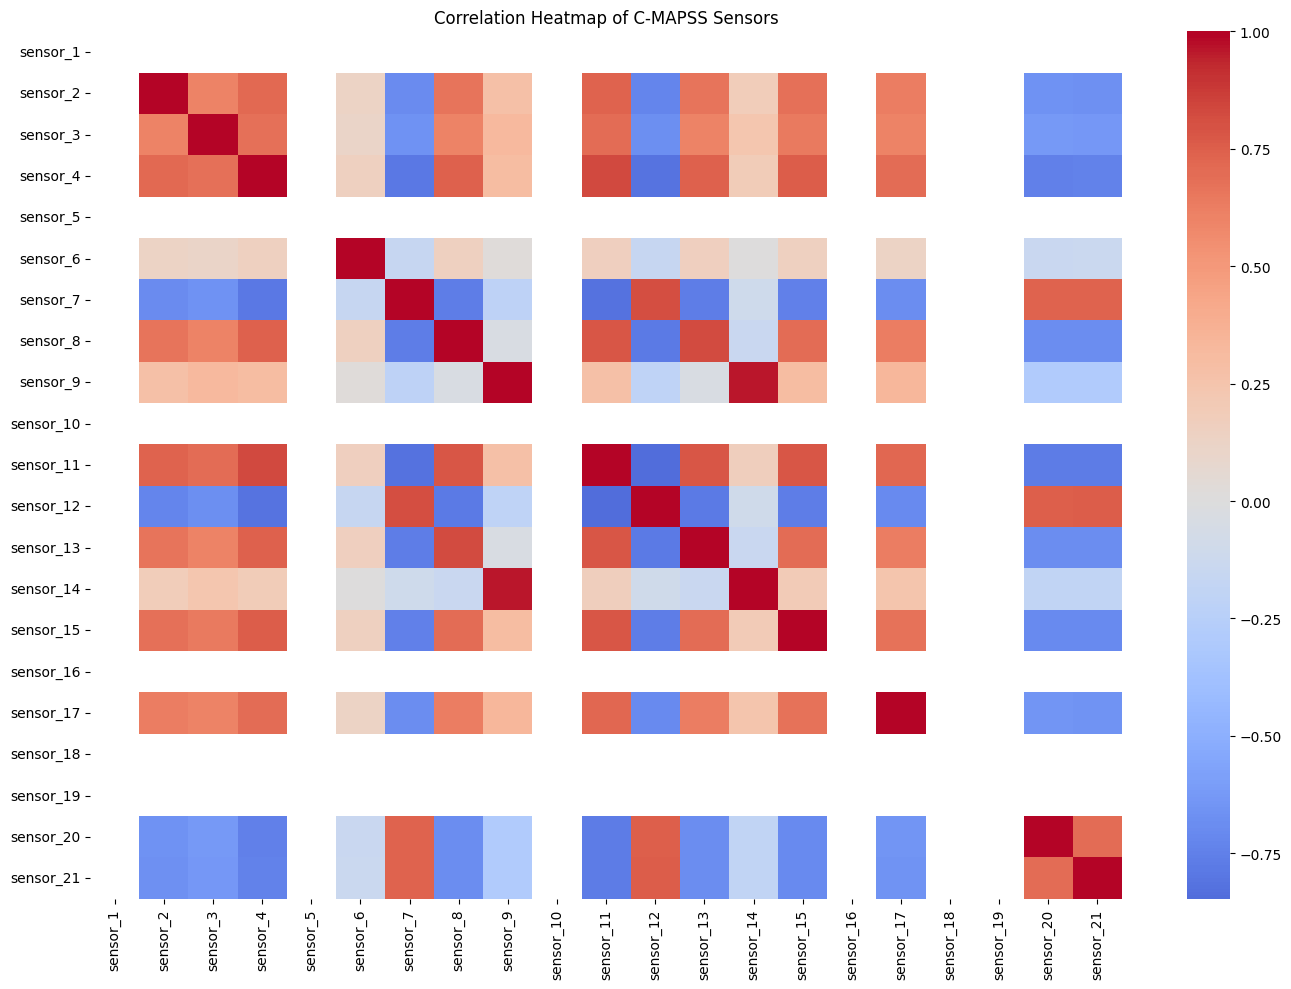

In [ ]:
# Correlation between sensor measurements
correlation = train_df[sensor_columns].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Heatmap of C-MAPSS Sensors")
plt.tight_layout()
plt.show()

## 5. Construct the RUL target
For each training observation, calculate RUL as the engine's final observed cycle minus its current cycle.

In [ ]:

# Step 5: Calculate Remaining Useful Life (RUL)

# Find the last observed cycle for each engine
last_cycle = train_df.groupby("engine_id")["cycle"].max()

# Add each engine's maximum cycle to its rows
train_df["max_cycle"] = train_df["engine_id"].map(last_cycle)

# Calculate RUL for every training observation
train_df["RUL"] = train_df["max_cycle"] - train_df["cycle"]

# Inspect the engineered target
print("Updated dataset shape:", train_df.shape)

display(
    train_df[
        ["engine_id", "cycle", "max_cycle", "RUL"]
    ].head(10)
)

# Verify the final cycle for a sample engine
sample_engine = 1
display(
    train_df[train_df["engine_id"] == sample_engine][
        ["engine_id", "cycle", "RUL"]
    ].tail()
)


Updated dataset shape: (20631, 28)


,engine_id,cycle,max_cycle,RUL
0,1,1,192,191
1,1,2,192,190
2,1,3,192,189
3,1,4,192,188
4,1,5,192,187
5,1,6,192,186
6,1,7,192,185
7,1,8,192,184
8,1,9,192,183
9,1,10,192,182


,engine_id,cycle,RUL
187,1,188,4
188,1,189,3
189,1,190,2
190,1,191,1
191,1,192,0


## 6. Prepare features and target
Use the three operating settings and 21 sensor measurements as input features, with calculated RUL as the regression target.

In [ ]:

# Step 6: Prepare input features and target

sensor_columns = [f"sensor_{i}" for i in range(1, 22)]
setting_columns = [f"setting_{i}" for i in range(1, 4)]

feature_columns = setting_columns + sensor_columns

X = train_df[feature_columns].copy()
y = train_df["RUL"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(feature_columns)

print("\nTarget summary:")
display(y.describe().to_frame("RUL"))


Feature matrix shape: (20631, 24)
Target shape: (20631,)

Input features:
['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']

Target summary:


,RUL
count,20631.000000
mean,107.807862
std,68.880990
min,0.000000
25%,51.000000
50%,103.000000
75%,155.000000
max,361.000000


## 7. Create an engine-wise validation split
Use `GroupShuffleSplit` so that all observations from an engine remain in either training or validation data, avoiding engine overlap between these two sets.

In [ ]:

from sklearn.model_selection import GroupShuffleSplit

# Keep each engine entirely within one split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X, y, groups=train_df["engine_id"])
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

train_engines = set(train_df.iloc[train_idx]["engine_id"])
val_engines = set(train_df.iloc[val_idx]["engine_id"])

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_val.shape[0])
print("Training engines:", len(train_engines))
print("Validation engines:", len(val_engines))
print("Engines overlap:", bool(train_engines & val_engines))


Training rows: 16561
Validation rows: 4070
Training engines: 80
Validation engines: 20
Engines overlap: False


## 8. Establish a baseline
Train a `DummyRegressor` that predicts the mean training RUL. This provides a reference point for the learned models.

In [ ]:

# Step 8: Baseline regression model

from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

baseline_model = DummyRegressor(strategy="mean")

# Train the baseline
baseline_model.fit(X_train, y_train)

# Predict RUL for validation engines
baseline_predictions = baseline_model.predict(X_val)

# Evaluate baseline performance
baseline_mae = mean_absolute_error(y_val, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_val, baseline_predictions))
baseline_r2 = r2_score(y_val, baseline_predictions)

print("Baseline Model: Mean RUL Prediction")
print(f"MAE:  {baseline_mae:.2f}")
print(f"RMSE: {baseline_rmse:.2f}")
print(f"R²:   {baseline_r2:.4f}")


Baseline Model: Mean RUL Prediction
MAE:  55.36
RMSE: 65.72
R²:   -0.0019


## 9. Train a Linear Regression model
Fit a linear regression model and evaluate its validation predictions.

In [ ]:

# Step 9: Linear Regression

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Predict validation RUL
linear_predictions = linear_model.predict(X_val)

# Evaluate the model
linear_mae = mean_absolute_error(y_val, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_val, linear_predictions))
linear_r2 = r2_score(y_val, linear_predictions)

print("Linear Regression Results")
print(f"MAE:  {linear_mae:.2f}")
print(f"RMSE: {linear_rmse:.2f}")
print(f"R²:   {linear_r2:.4f}")


Linear Regression Results
MAE:  30.11
RMSE: 38.13
R²:   0.6626


## 10. Train a Decision Tree regressor
Fit a constrained decision tree and evaluate its validation predictions.

In [ ]:

# Step 10: Decision Tree Regression

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_leaf=10,
    random_state=42
)

# Train the model
tree_model.fit(X_train, y_train)

# Predict validation RUL
tree_predictions = tree_model.predict(X_val)

# Evaluate the model
tree_mae = mean_absolute_error(y_val, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_val, tree_predictions))
tree_r2 = r2_score(y_val, tree_predictions)

print("Decision Tree Regression Results")
print(f"MAE:  {tree_mae:.2f}")
print(f"RMSE: {tree_rmse:.2f}")
print(f"R²:   {tree_r2:.4f}")


Decision Tree Regression Results
MAE:  29.28
RMSE: 39.89
R²:   0.6308


## 11. Train a Random Forest regressor
Train the Random Forest model used for the subsequent feature-importance and error-analysis experiments.

In [ ]:

# Step 11: Random Forest Regression

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict validation RUL
rf_predictions = rf_model.predict(X_val)

# Evaluate the model
rf_mae = mean_absolute_error(y_val, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_predictions))
rf_r2 = r2_score(y_val, rf_predictions)

print("Random Forest Regression Results")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.4f}")


Random Forest Regression Results
MAE:  25.75
RMSE: 35.29
R²:   0.7111


## 12. Compare the initial regression models
Compare the baseline, Linear Regression, Decision Tree and Random Forest using MAE, RMSE and R².

In [ ]:

# Step 12: Compare all models

results = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        tree_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        tree_r2,
        rf_r2
    ]
})

results = results.sort_values("RMSE").reset_index(drop=True)
display(results.round(4))


,Model,MAE,RMSE,R2
0,Random Forest,25.7539,35.2865,0.7111
1,Linear Regression,30.1113,38.1325,0.6626
2,Decision Tree,29.2824,39.8915,0.6308
3,Baseline,55.3633,65.7154,-0.0019


## 13. Interpret Random Forest feature importance
Rank the input features by the importance scores learned by the Random Forest model.

Top 10 features for RUL prediction:


,Feature,Importance
13,sensor_11,0.5098
11,sensor_9,0.1370
6,sensor_4,0.0786
14,sensor_12,0.0422
16,sensor_14,0.0345
9,sensor_7,0.0313
17,sensor_15,0.0256
23,sensor_21,0.0240
5,sensor_3,0.0211
4,sensor_2,0.0197


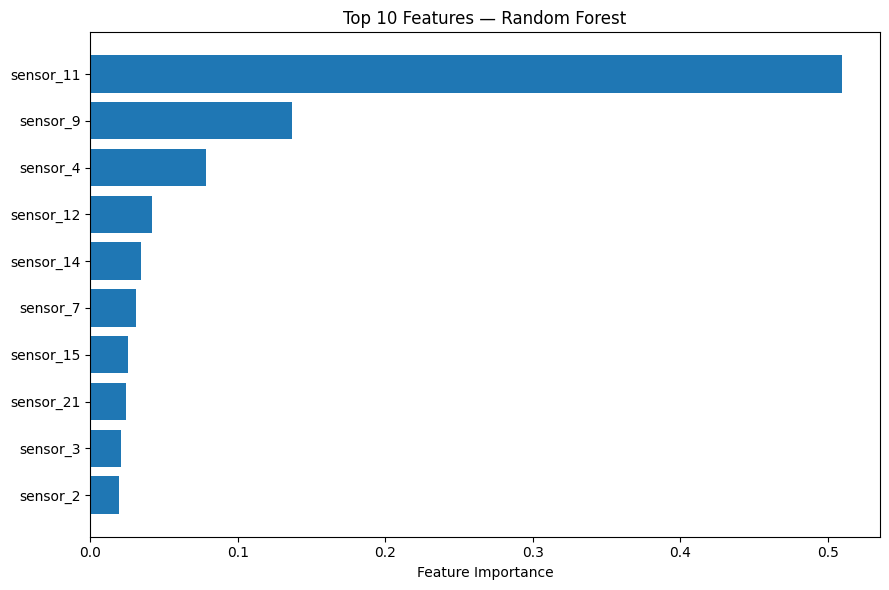

In [ ]:

# Step 13: Feature importance from Random Forest

importance_df = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print("Top 10 features for RUL prediction:")
display(importance_df.head(10).round(4))

# Visualize the top 10 features
top_features = importance_df.head(10).sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 10 Features — Random Forest")
plt.tight_layout()
plt.show()


## 14. Actual versus predicted RUL
Visualize validation predictions against the true RUL values. The diagonal reference line represents perfect predictions.

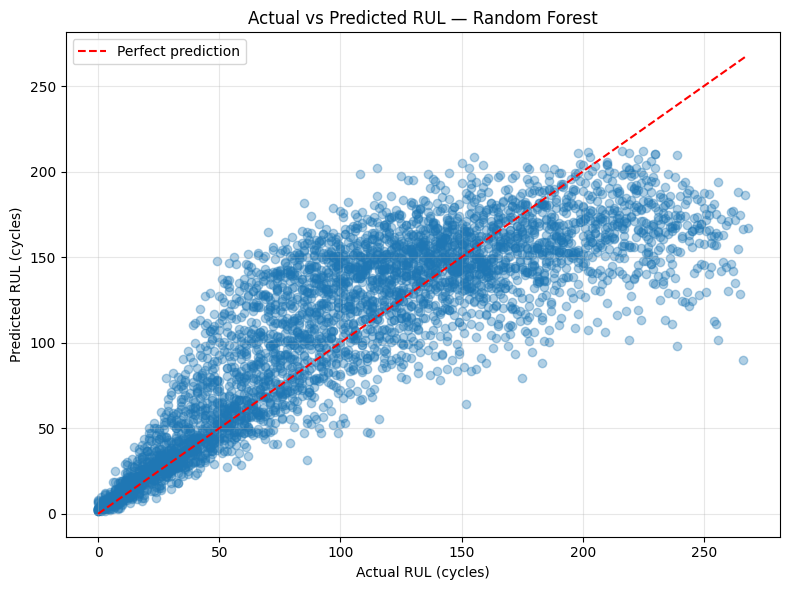

In [ ]:

# Step 14: Actual vs Predicted RUL

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    rf_predictions,
    alpha=0.35
)

# Ideal prediction line
min_value = min(y_val.min(), rf_predictions.min())
max_value = max(y_val.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Actual vs Predicted RUL — Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 15. Residual analysis
Inspect the difference between actual and predicted RUL to understand prediction errors.

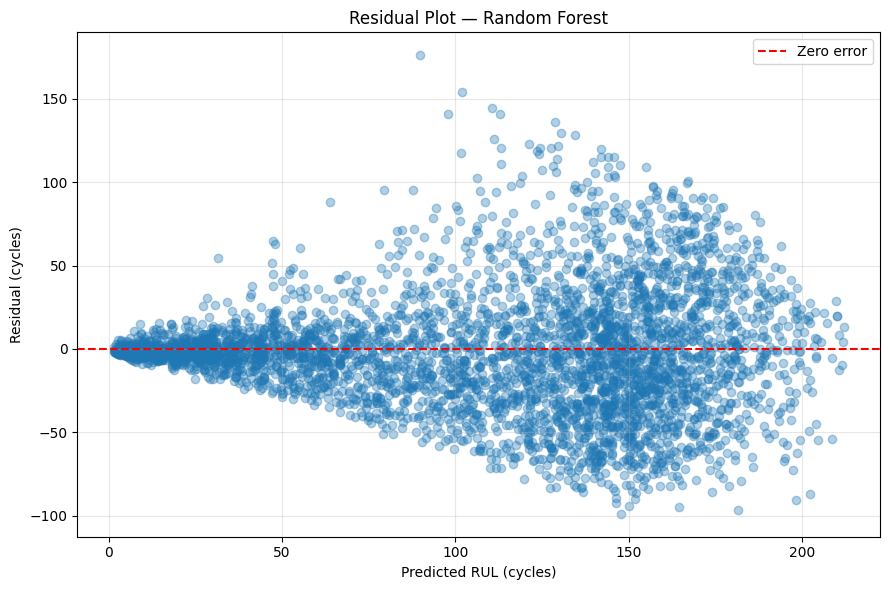

Mean residual: -2.29
Median residual: -2.99


In [ ]:

# Step 15: Residual analysis

residuals = y_val.to_numpy() - rf_predictions

plt.figure(figsize=(9, 6))

plt.scatter(
    rf_predictions,
    residuals,
    alpha=0.35
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero error"
)

plt.xlabel("Predicted RUL (cycles)")
plt.ylabel("Residual (cycles)")
plt.title("Residual Plot — Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Mean residual:", round(residuals.mean(), 2))
print("Median residual:", round(np.median(residuals), 2))


## 16. Overestimation and underestimation analysis
Count how often the model predicts a higher or lower RUL than the actual value.

In [ ]:

# Step 16: Overestimation vs Underestimation

actual_rul = y_val.to_numpy()
predicted_rul = rf_predictions

# Positive difference means overestimation
prediction_error = predicted_rul - actual_rul

overestimated = prediction_error > 0
underestimated = prediction_error < 0
exact = prediction_error == 0

print("Total validation observations:", len(actual_rul))

print("\nOverestimation:")
print("Count:", overestimated.sum())
print("Percentage:", round(overestimated.mean() * 100, 2), "%")
print(
    "Mean overestimation:",
    round(prediction_error[overestimated].mean(), 2),
    "cycles"
)

print("\nUnderestimation:")
print("Count:", underestimated.sum())
print("Percentage:", round(underestimated.mean() * 100, 2), "%")
print(
    "Mean underestimation magnitude:",
    round(-prediction_error[underestimated].mean(), 2),
    "cycles"
)

print("\nExact predictions:", exact.sum())


Total validation observations: 4070

Overestimation:
Count: 2337
Percentage: 57.42 %
Mean overestimation: 24.42 cycles

Underestimation:
Count: 1733
Percentage: 42.58 %
Mean underestimation magnitude: 27.55 cycles

Exact predictions: 0


## 17. Evaluate on the official FD001 test set
Load the official test engines and their supplied RUL targets. The model predicts RUL from each engine's final observed row.

In [ ]:

# Step 17: Evaluate Random Forest on the official FD001 test set

data_dir = "/content/CMAPSSData"

# Load test data
test_df = pd.read_csv(
    f"{data_dir}/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Load true RUL for each test engine
test_rul = pd.read_csv(
    f"{data_dir}/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)["RUL"]

# Select the final observed row for each engine
test_last = (
    test_df.sort_values(["engine_id", "cycle"])
    .groupby("engine_id")
    .tail(1)
    .sort_values("engine_id")
    .reset_index(drop=True)
)

X_test = test_last[feature_columns]

# Predict RUL for each test engine
test_predictions = rf_model.predict(X_test)

# Compare predictions with the supplied RUL values
test_mae = mean_absolute_error(test_rul, test_predictions)
test_rmse = np.sqrt(mean_squared_error(test_rul, test_predictions))
test_r2 = r2_score(test_rul, test_predictions)

print("Official FD001 Test Results")
print("Test engines:", len(test_last))
print("True RUL values:", len(test_rul))
print(f"MAE:  {test_mae:.2f}")
print(f"RMSE: {test_rmse:.2f}")
print(f"R²:   {test_r2:.4f}")

# Show actual and predicted RUL for sample engines
test_comparison = pd.DataFrame({
    "Engine ID": test_last["engine_id"],
    "Actual RUL": test_rul,
    "Predicted RUL": test_predictions
})

display(test_comparison.head(10).round(2))


Official FD001 Test Results
Test engines: 100
True RUL values: 100
MAE:  24.30
RMSE: 32.97
R²:   0.3705


,Engine ID,Actual RUL,Predicted RUL
0,1,112,175.40
1,2,98,149.94
2,3,69,59.89
3,4,82,100.30
4,5,91,126.41
5,6,93,124.13
6,7,91,129.71
7,8,95,116.41
8,9,111,125.59
9,10,96,137.27


## 18. Official test-set visualization
Compare the Random Forest predictions with the supplied true RUL values for the official test engines.

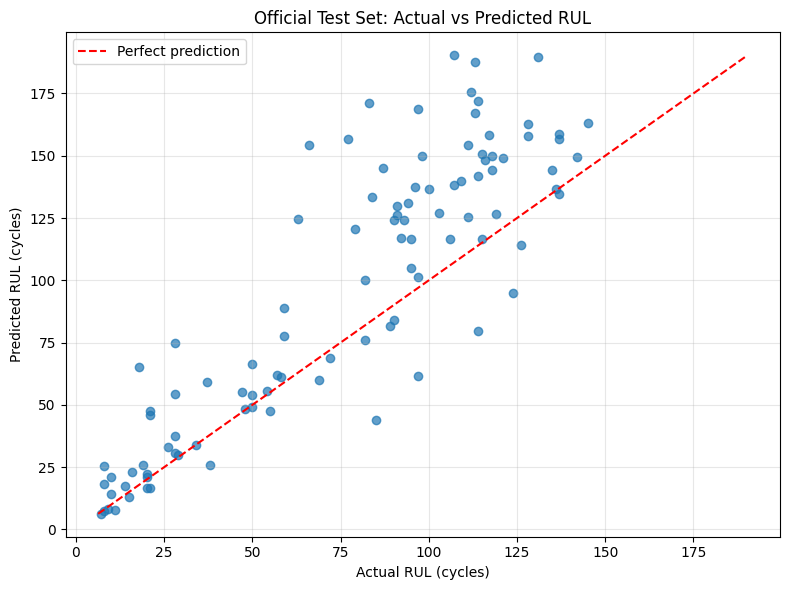

In [ ]:

# Step 18: Actual vs Predicted RUL on the official test set

plt.figure(figsize=(8, 6))

plt.scatter(
    test_rul,
    test_predictions,
    alpha=0.7
)

min_value = min(test_rul.min(), test_predictions.min())
max_value = max(test_rul.max(), test_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Official Test Set: Actual vs Predicted RUL")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 19. Feature-selection experiment
Retrain Random Forest using the ten highest-ranked features and compare its validation performance with the full-feature model.

In [ ]:

# Step 19: Feature-selection experiment

# Select the 10 highest-ranked features
selected_features = importance_df.head(10)["Feature"].tolist()

print("Selected features:")
print(selected_features)

# Prepare reduced training and validation data
X_train_selected = X_train[selected_features]
X_val_selected = X_val[selected_features]

# Train a Random Forest using only the selected features
rf_selected = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_selected.fit(X_train_selected, y_train)

# Evaluate on the same validation set
selected_predictions = rf_selected.predict(X_val_selected)

selected_mae = mean_absolute_error(y_val, selected_predictions)
selected_rmse = np.sqrt(mean_squared_error(y_val, selected_predictions))
selected_r2 = r2_score(y_val, selected_predictions)

print("\nRandom Forest with Selected Features")
print(f"Features used: {len(selected_features)}")
print(f"MAE:  {selected_mae:.2f}")
print(f"RMSE: {selected_rmse:.2f}")
print(f"R²:   {selected_r2:.4f}")


Selected features:
['sensor_11', 'sensor_9', 'sensor_4', 'sensor_12', 'sensor_14', 'sensor_7', 'sensor_15', 'sensor_21', 'sensor_3', 'sensor_2']

Random Forest with Selected Features
Features used: 10
MAE:  26.07
RMSE: 35.55
R²:   0.7068


Feature Selection Experiment: Random Forest was retrained using the 10 highest-ranked features identified from the training data. Compared with the full 24-feature model, the reduced model achieved an MAE of 26.07, RMSE of 35.55, and R² of 0.7068. Performance remained similar, but the full model performed slightly better. This demonstrates that reducing the feature count does not necessarily improve predictive accuracy.

## 20. Learning-curve analysis
Train Random Forest models using increasing numbers of complete training-engine histories and compare training and validation MAE.

16 engines | 3401 rows | Training MAE: 12.89 | Validation MAE: 27.02
32 engines | 6848 rows | Training MAE: 17.90 | Validation MAE: 26.26
48 engines | 10190 rows | Training MAE: 19.19 | Validation MAE: 26.05
64 engines | 13269 rows | Training MAE: 19.78 | Validation MAE: 25.59
80 engines | 16561 rows | Training MAE: 20.42 | Validation MAE: 25.75


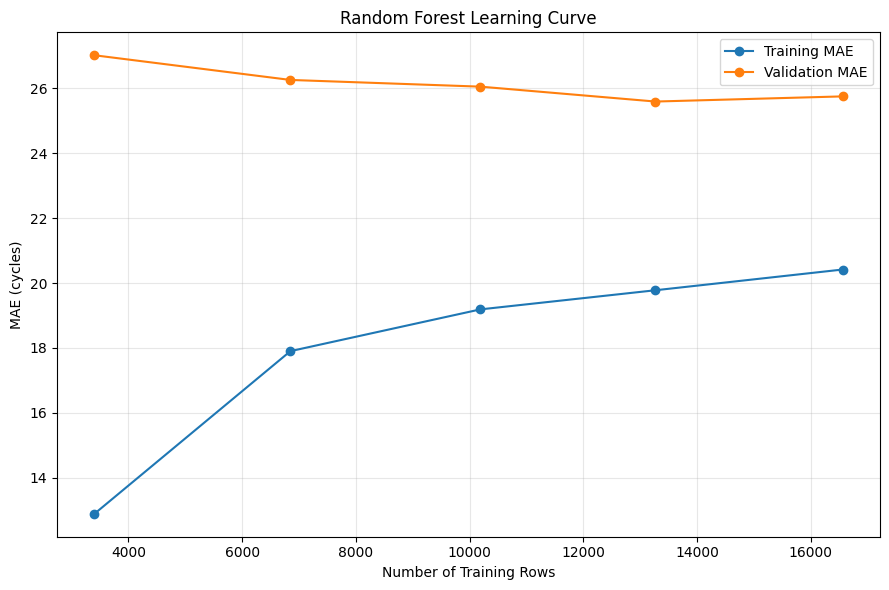

In [ ]:

# Step 20: Learning Curve Analysis
# Use different numbers of complete training-engine histories

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import numpy as np

# Recover the engine IDs corresponding to training rows
train_engine_ids = train_df.loc[X_train.index, "engine_id"]
unique_engines = np.sort(train_engine_ids.unique())

fractions = [0.2, 0.4, 0.6, 0.8, 1.0]
training_sizes = []
training_mae = []
validation_mae = []

rng = np.random.RandomState(42)
shuffled_engines = rng.permutation(unique_engines)

for fraction in fractions:
    n_engines = max(1, int(len(unique_engines) * fraction))
    selected_engines = shuffled_engines[:n_engines]

    # Keep all observations for the selected engines
    selected_rows = train_engine_ids[
        train_engine_ids.isin(selected_engines)
    ].index

    X_subset = X_train.loc[selected_rows]
    y_subset = y_train.loc[selected_rows]

    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_subset, y_subset)

    train_pred = model.predict(X_subset)
    val_pred = model.predict(X_val)

    training_sizes.append(len(X_subset))
    training_mae.append(mean_absolute_error(y_subset, train_pred))
    validation_mae.append(mean_absolute_error(y_val, val_pred))

    print(
        f"{n_engines} engines | "
        f"{len(X_subset)} rows | "
        f"Training MAE: {training_mae[-1]:.2f} | "
        f"Validation MAE: {validation_mae[-1]:.2f}"
    )

# Plot the learning curve
plt.figure(figsize=(9, 6))
plt.plot(training_sizes, training_mae, marker="o", label="Training MAE")
plt.plot(training_sizes, validation_mae, marker="o", label="Validation MAE")
plt.xlabel("Number of Training Rows")
plt.ylabel("MAE (cycles)")
plt.title("Random Forest Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 21. Ensemble model experiments
Import the estimators and metrics needed to train Gradient Boosting, Voting and Stacking regressors.

In [ ]:
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor,
    VotingRegressor,
    StackingRegressor
)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 21.1 Train ensemble regressors
Fit the Gradient Boosting, Voting and Stacking models using the same training split.

In [ ]:
# 1. Gradient Boosting
gbr_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)
gbr_model.fit(X_train, y_train)

# 2. Voting Regressor
voting_model = VotingRegressor([
    ("linear", LinearRegression()),
    ("tree", DecisionTreeRegressor(
        max_depth=10, min_samples_leaf=10, random_state=42
    )),
    ("forest", RandomForestRegressor(
        n_estimators=100, max_depth=15,
        min_samples_leaf=5, random_state=42, n_jobs=-1
    ))
])
voting_model.fit(X_train, y_train)

# 3. Stacking Regressor
stacking_model = StackingRegressor(
    estimators=[
        ("linear", LinearRegression()),
        ("tree", DecisionTreeRegressor(
            max_depth=10, min_samples_leaf=10, random_state=42
        )),
        ("forest", RandomForestRegressor(
            n_estimators=100, max_depth=15,
            min_samples_leaf=5, random_state=42, n_jobs=-1
        ))
    ],
    final_estimator=LinearRegression(),
    cv=3,
    n_jobs=-1
)
stacking_model.fit(X_train, y_train)

print("All three ensemble models trained successfully.")

All three ensemble models trained successfully.


### 21.2 Compare all six regression models
Evaluate the six trained models on the validation set using MAE, RMSE and R².

In [ ]:
models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,  # Change if your decision tree variable has another name
    "Random Forest": rf_model,
    "Gradient Boosting": gbr_model,
    "Voting Regressor": voting_model,
    "Stacking Regressor": stacking_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_val)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2 Score": r2_score(y_val, predictions)
    })

comparison_df = pd.DataFrame(results).sort_values("MAE")
display(comparison_df.round(3))

,Model,MAE,RMSE,R2 Score
2,Random Forest,25.754,35.287,0.711
5,Stacking Regressor,26.213,35.219,0.712
3,Gradient Boosting,26.366,35.629,0.705
4,Voting Regressor,26.826,35.952,0.700
1,Decision Tree,29.282,39.891,0.631
0,Linear Regression,30.111,38.133,0.663


### Results and Model Selection

Six regression models were compared using the same validation set. Random Forest achieved the lowest MAE of 25.754 cycles, while Stacking Regressor achieved the lowest RMSE of 35.219 cycles and the highest R² of 0.712. Random Forest was selected as the primary model because it produced the lowest average absolute prediction error.

On the official FD001 test set, Random Forest achieved an MAE of 24.30 cycles, an RMSE of 32.97 cycles, and an R² of 0.371. The results indicate that the model can estimate remaining useful life, although prediction accuracy varies across engines.